# Week 8 - Trees and Ensembles

**Thomas Sinclair**

### Aims

By the end of this notebook you will be able to understand: 

>* The Basics of Decision Trees
>* Cost Complexity Pruning
>* Ensembles (bagging, random forests, voting)


1. [Setup](#setup)

2. [Decision Trees](#intro)

3. [Ensembles](#majVot)

You may complete the worksheets together in teams of 2-3. When completing worksheets:

>- You will have tasks tagged by (CORE) and (EXTRA). 
>- Your primary aim is to complete the (CORE) components during the WS session, afterwards you can try to complete the (EXTRA) tasks for your self-learning process. 
>- In some Exercises, you will see some beneficial hints at the bottom of questions.

Instructions for submitting your workshops can be found at the end of worksheet. As a reminder, you must submit a pdf of your notebook on Learn by 16:00 PM on the first Monday after the day workshop was given.

# Setup <a id='setup'></a>

Let's load the packages needed for this workshop (more will be loaded later in the workshop).

In [2]:
# Display plots inline
%matplotlib inline  

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# some new libraries and modules for this week
from sklearn.tree import export_graphviz, DecisionTreeClassifier

# Introduction to Decision Trees <a id='intro'></a>

Decision trees provide a simple, interpretable model for both classification and regression tasks. They are able to capture nonlinear relationships between the features and target variables, by learning simple decision rules and assuming piecewise constant approximations. The deeper the tree, the more complex the decision rules and the better the fit on the training data.

Decision trees require little preprocessing and feature engineering. While other methods often require standardization, this is not the case for trees, and some tree and algorithm combinations can even support missing values. Decision trees able to handle both numerical and categorical data. However, sklearn does not implent more advanced methods for multi-class categorical features, and one-hot encoding must be used; if the number of features is large, this may result in many features and complex trees that suffer from overfitting. 

To learn the decision tree, sklearn uses an optimized version of the Classification and Regression Tree (CART) algorithm, which is a greedy algorithm where locally optimal decisions are made at each node, starting from the root down to the leaves. At each node/step, CART uses binary spliting and finds the threshold yielding the largest information gain. For more information on sklearn's implementation of decision trees, see https://scikit-learn.org/stable/modules/tree.html#tree-classification.

The sklearn implementation supports both regression tasks through [`DecisionTreeRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn.tree.DecisionTreeRegressor) and classication through [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier). In this workshop, we will focus on **classification**. 

Let's start by loading data to explore the `DecisionTreeClassifier`.

##  Palmer Penguin Data

The palmer penguins dataset contains information for 344 penguins from 3 different species and from 3 islands in the Palmer Archipelago, Antarctica.

In [3]:
# Load the data
penguins = sns.load_dataset("penguins")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


Let's start with some basic EDA.

In [4]:
penguins.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


Notice that there are some missing values. For simplicity, we will remove them.  

In [5]:
# dropna values
penguins_rm = penguins.dropna()
penguins_rm.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


We will focus on the task of classifying species. Notice that there are four numerical features and two categorical features. For simplicity, we will focus on the numerical features only. Before any further EDA, we split our data into a training and test set.

In [6]:
# Split into train and test sets

# Feature matrix and response vector
X, y = penguins_rm.drop(["island", "sex", "species"], axis=1), penguins_rm['species']

# Stratify split
X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle= True, test_size = 0.2, random_state=0)

### 🚩 Exercise 1 (CORE)

- Draw a pairplot, setting `hue = "species"`, to explore the numerical features relation with species. 
- Comment on any relationships that you observe.


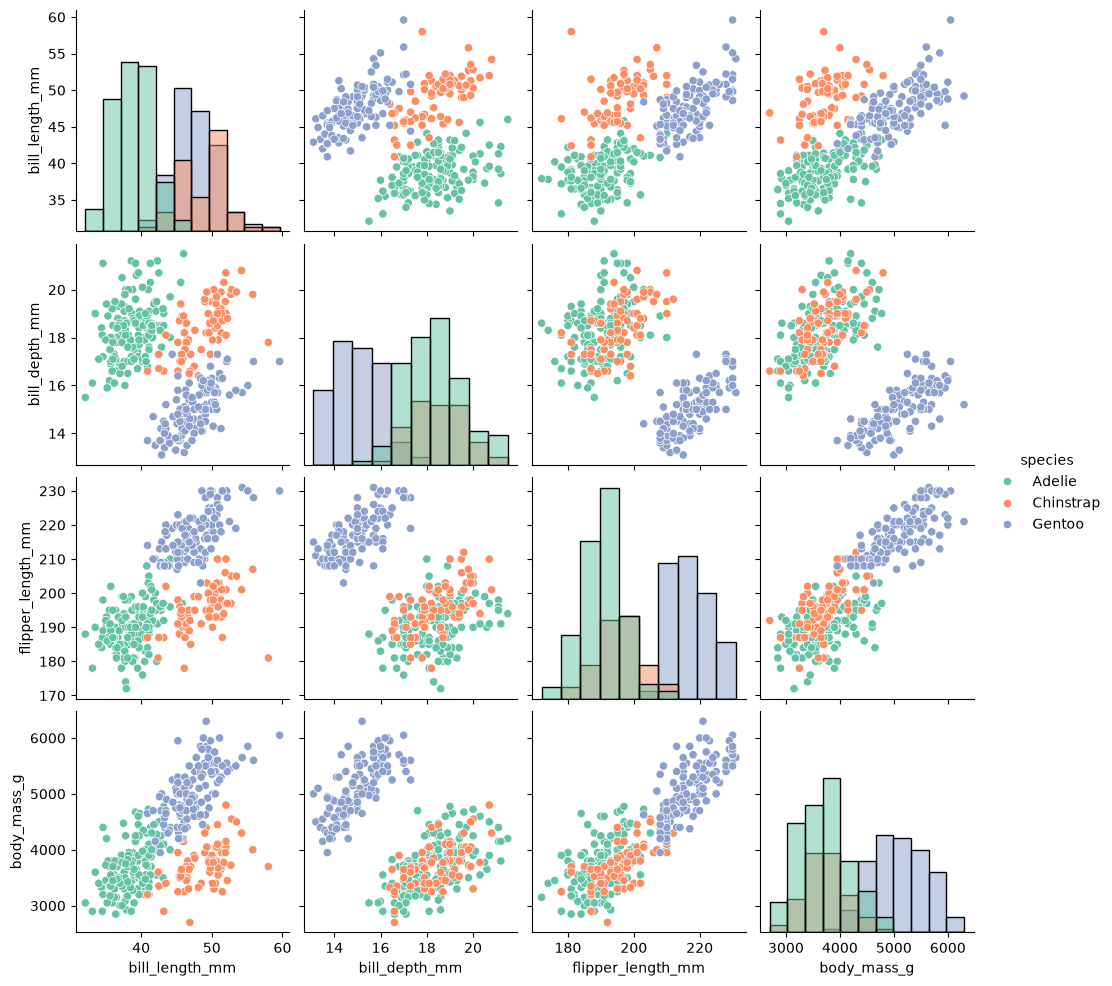

In [7]:
# Code for your answer here

sns.pairplot(penguins_rm, hue="species", palette="Set2", diag_kind="hist")

_Type your answer here_

When looking at the pairplot, and including a colour distinction beyween species we are trying to see the effect of the classification of the species onotheer factors. We are looking for features, where the species are seperable, meaning clear differnece between species. This will help us build a robust classifier, that can accurately predict the species given input. Some examples of features which seperate the species, are bill length, against bill depth, agains flipper length, and agaisnt body mass. Thus indicating bill length is a god feature to predict species. A poor example is the graph  with bill depth against flipper length, where the chinstrap an Gentoo species overlap, thus would be hard to distinguish the difference between speciies looking purely at these features.

## Classification Trees

Recall from lectures that a number of parameters affect the shape of a decision tree:

- `max_depth` : the maximum depth of the tree. 

- `min_samples_split` : the minimum number of samples required to split an internal node

- `min_samples_leaf` : the minimum number of samples required to be at a leaf node. A split point at any depth will only be considered if it leaves at least min_samples_leaf training samples in each of the left and right branches. 

- `max_leaf_nodes` : the maximum number of leaf nodes. 

- `min_impurity_decrease` : A node will be split if this split induces a decrease of the impurity greater than or equal to this value.

As usual, once we create our `DecisionTreeClassifier` object, we can fit the tree by calling `.fit()`. Once fit, the tree will have a number of attributes and we can call additional methods such as `.predict()` or  `.predict_proba()` to predict hard or soft labels, respectively, for any new data. 

Let's fit our first decision tree. In the following code, we fit a simple tree of depth 2 by specifying `max_depth=2`. 

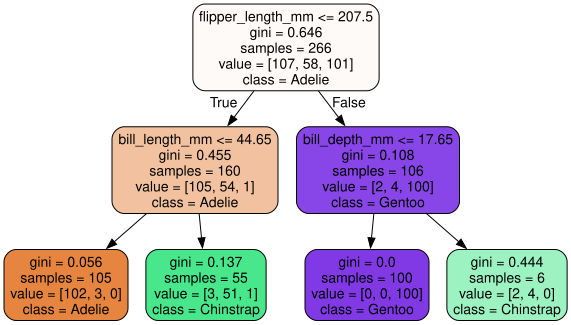

In [8]:
# If you need to install graphviz
#! pip install graphviz
import graphviz

# Decision tree with max depth of 2
tree_clf = DecisionTreeClassifier(max_depth = 2,random_state=0)
tree_clf.fit(X_train, y_train)

# Plot the decision tree
tree_data = export_graphviz(
 tree_clf,
 rounded = True, filled = True, feature_names=X_train.columns, class_names = tree_clf.classes_
 )
graphviz.Source(tree_data) 

**NOTE:** If you are working locally and [inkscape](https://inkscape.org/release/inkscape-1.4/) is not installed, you will have issues in exporting the notebook to PDF when graphviz images are included. In this case, please either install inkscape or use the `plot_tree` function below to plot the tree instead. 

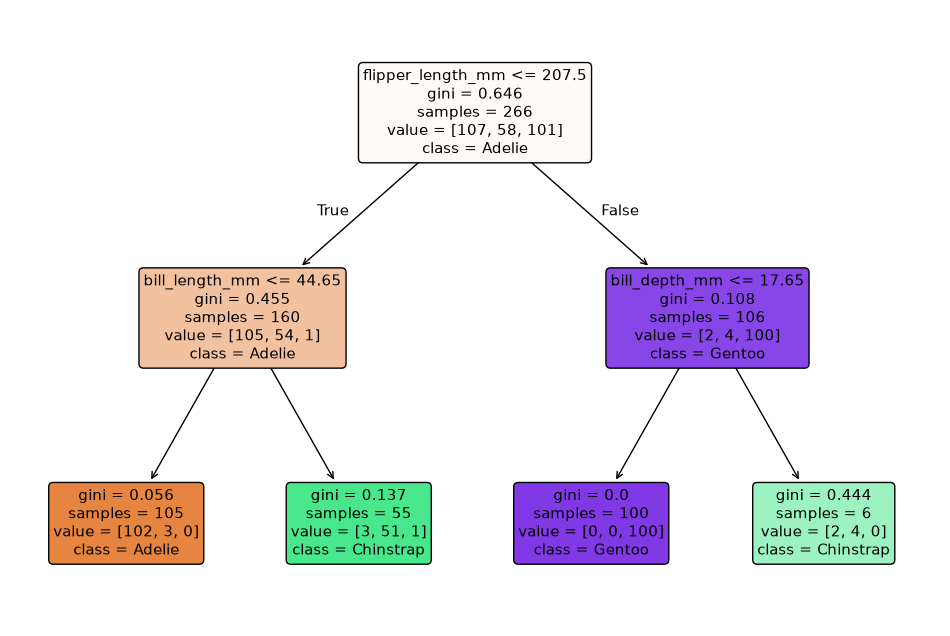

In [9]:
from sklearn.tree import plot_tree

plt.figure(figsize=(12,8))
plot_tree(tree_clf, rounded = True, filled = True, feature_names=X_train.columns, class_names = tree_clf.classes_)
plt.show()

### 🚩 Exercise 2  (CORE)

Below, we print out the first five rows of the test data. Based on the fitted tree above (not using `.predict()`!!), what is the classified species of each penguin/row? what path along the decision tree is taken to classify the penguin?

In [10]:
X_test.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
62,37.6,17.0,185.0,3600.0
60,35.7,16.9,185.0,3150.0
283,54.3,15.7,231.0,5650.0
107,38.2,20.0,190.0,3900.0
65,41.6,18.0,192.0,3950.0



_Type your answer here_

The first penguin (row), starting at the top of the tree has flipper length of 185, satisfying the threshold of 207.5, thus go down True branch. This first penguine also has bill length of 37.6 which also satifies the next threshold of 44.65, therefore follow True path. Thus, in the class Adelle.

Now doing the same process for the next few penguines. The second is also an Adelle, third a Gentoo, fourth a Adelle, and finally the fith being an Adelle too.

### 🚩 Exercise 3  (CORE) 

Fit a new decision tree, again with a depth 2, but change the criterion to measure the quality of a split to entropy. How has the tree stucture changed?

**Hint:** when creating the decision tree object, set the option `criterion`.

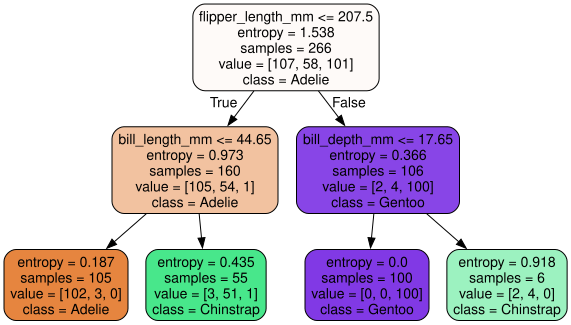

In [11]:
# Code for your answer here
# Decision tree with max depth of 2
tree_clf_e = DecisionTreeClassifier(criterion = 'entropy', max_depth = 2,random_state=0)
tree_clf_e.fit(X_train, y_train)

# Plot the decision tree
tree_data = export_graphviz(
 tree_clf_e,
 rounded = True, filled = True, feature_names=X_train.columns, class_names = tree_clf_e.classes_
 )
graphviz.Source(tree_data) 

_Type your answer here_

The strucutre of the treee hasnt changed. This is expected, especially for such a shallow decsiion tree. As gini and entorpy criterion are closely related.

### 🚩 Exercise 4  (CORE) 

- Create two functions, one to compute the Gini index and another to compute the entropy, based on a vector of counts representing the number of observations in each category. 

- For each leaf node in the trees fitted above, use your functions to compute the Gini index and entropy based on the counts reported. If your functions are correct, it should match the numbers reported in the tree.

**RECALL**

- **Gini Index**: is a measure of total variance across the $C$ classes, defined as:

$G(R_m) = \sum_{c=1}^{C} \widehat{p}_{m,c} (1 - \widehat{p}_{m,c}) = 
1 - \sum_{c=1}^{C} \widehat{p}_{m,c}^2$ 

where $\widehat{p}_{m,c}$ is the proportion of training observations in the $m$ th region (belonging to $m$ th node) coming from the $c$ th class.

- **Entropy**: is an information theoretic measure defined as:

$H(R_m) = - \sum_{c=1}^{C} \widehat{p}_{m,c} \log_2 \widehat{p}_{m,c}.$

In [12]:
# Code for your answer here
def Gini(y):
    """Calculate the Gini impurity of a set of labels."""
    n = np.sum(y)
    p = y / n
    return 1 - np.sum(p ** 2)

def Entropy(y):
    """Calculate the entropy of a set of labels."""
    n = np.sum(y)
    p = y / n
    return -np.sum(p * np.log2(p + 1e-8))  # Add a small value to avoid log(0)

print(Gini([107,58,101]))
print(Gini([105,54,1]))
print(Gini([2,4,100]))
print(Gini([102,3,0]))
print(Gini([3,51,1]))
print(Gini([0,0,100]))
print(Gini([2,4,0]))

print(' ')

print(Entropy([107,58,101]))
print(Entropy([105,54,1]))
print(Entropy([2,4,100]))
print(Entropy([102,3,0]))
print(Entropy([3,51,1]))
print(Entropy([0,0,100]))
print(Entropy([2,4,0]))

0.6464752105828481
0.45539062500000005
0.10822356710573156
0.05551020408163265
0.13685950413223147
0.0
0.4444444444444444
 
1.5380672605652521
0.9734298986579594
0.365791930362802
0.1871762280193099
0.43502185310363656
-1.442695024907551e-08
0.918295805200589


Note that our fitted `DecisionTreeClassifier` stores the tree as an attribute, which can be accessed by calling `.tree_`. For more information on how `sklearn` stores a tree, see [here](https://scikit-learn.org/stable/auto_examples/tree/plot_unveil_tree_structure.html#sphx-glr-auto-examples-tree-plot-unveil-tree-structure-py). The fitted tree has a number of attributes, including `.impurity` providing the impurity for all nodes.    

In [13]:
# The impurity values for all nodes are accessible in the impurity attribute of the tree.
print(tree_clf.tree_.impurity)
print(tree_clf_e.tree_.impurity)

[0.64647521 0.45539063 0.0555102  0.1368595  0.10822357 0.
 0.44444444]
[1.5380673  0.97342994 0.18717626 0.4350219  0.36579197 0.
 0.91829583]


### 🚩 Exercise 5  (EXTRA - Feedback will be provided)

Increase the maximum tree depth to 10.

- Fit and visualise the tree.

- What is the depth of the tree? **Hint**: check the available methods for a `DecisionTreeClassifier`. 

- How does the accuracy on both the train and test data compare with our previous tree with a depth of 2?

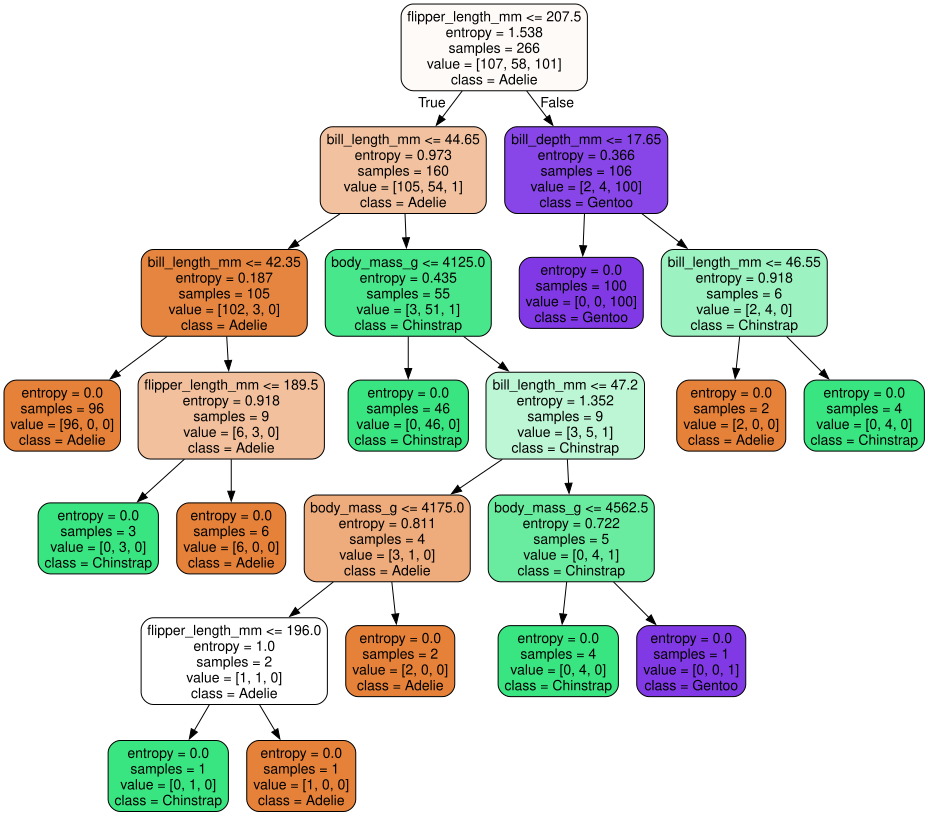

In [14]:
# Code for your answer here
# Code for your answer here
# Decision tree with max depth of 10
tree_clf_e = DecisionTreeClassifier(criterion = 'entropy', max_depth = 10,random_state=0)
tree_clf_e.fit(X_train, y_train)

# Plot the decision tree
tree_data = export_graphviz(
 tree_clf_e,
 rounded = True, filled = True, feature_names=X_train.columns, class_names = tree_clf_e.classes_
 )
graphviz.Source(tree_data) 

_Type your answer here_
Plotted to compare for exercise 7.

## Cost Complexity Pruning

Instead of using cross-validation to fit and tune the tree depth and shape across a range of values, a more effective and computationally efficient strategy is **cost complexity pruning**. Recall that in cost complexity pruning, we start by constructing a complex tree, and sequentially prune back the tree by snipping off the branches that minimize the cost complexity. This produces a sequence of nested trees, with each one associated to range of values of $\alpha$ (i.e. each tree is the optimal, unique tree for this range of $\alpha$).

We can perform cost complexity pruning in `sklearn` by using the method `cost_complexity_pruning_path()` on our decision tree object. Recall that a larger value of $\alpha$ implies more regularization and more shallow trees.

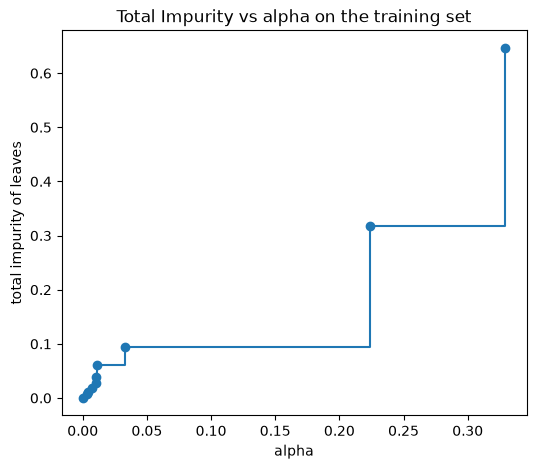

In [15]:
# Cost complexity pruning
tree_clf = DecisionTreeClassifier()
tree_clf.fit(X_train, y_train)
path = tree_clf.cost_complexity_pruning_path(X_train,y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

fig, ax = plt.subplots(figsize=(6,5))
ax.plot(ccp_alphas, impurities, marker="o", drawstyle="steps-post")
ax.set_xlabel("alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs alpha on the training set")
plt.show()

Run the following code to understand the depth and number of nodes in each tree in the sequence.

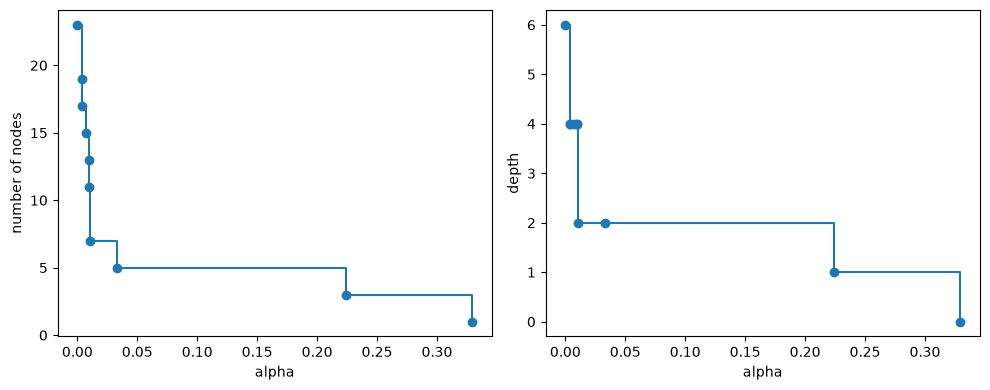

In [16]:
# Fit and store the decision tree for each value of alpha
clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(ccp_alpha=ccp_alpha)
    clf.fit(X_train, y_train)
    clfs.append(clf)

# Plot the depth and number of nodes for each tree for in the sequence as a function of alpha
node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]
fig, ax = plt.subplots(1,2, figsize=(10,4))
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth")
fig.tight_layout()

We see that each $\alpha$ is associated with unique number of nodes and increasing $\alpha$ reduces the size of tree (number of nodes). Thus, it is often more intutive to plot the total impurity as a function of the tree size.

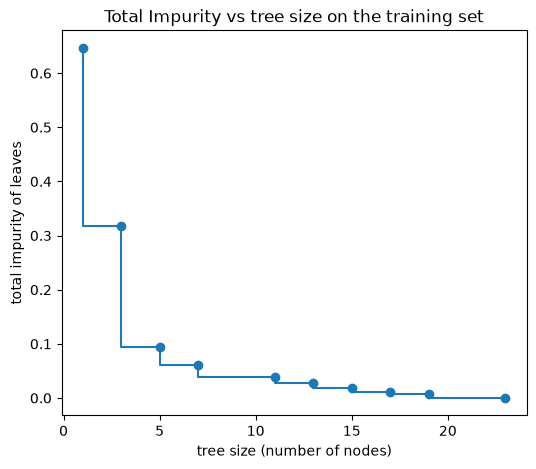

In [17]:
fig, ax = plt.subplots(figsize=(6,5))
ax.plot(node_counts, impurities, marker="o", drawstyle="steps-post")
ax.set_xlabel("tree size (number of nodes)")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs tree size on the training set")
plt.show()

Run the following code to compute the accuracy of each tree in the sequence on both the training and test set. 

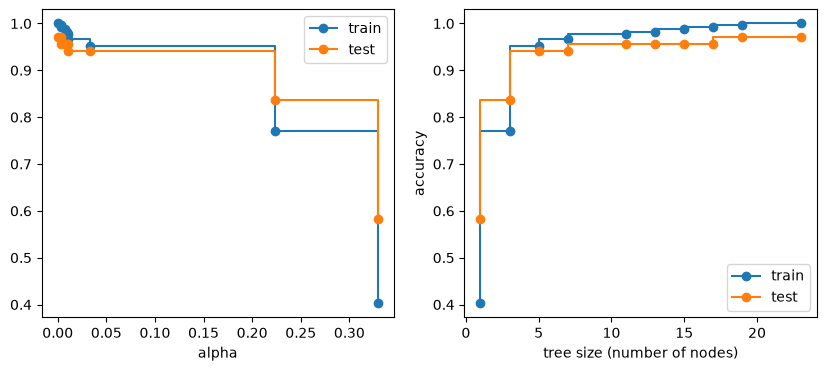

In [18]:
train_scores = [clf.score(X_train, y_train) for clf in clfs]
test_scores = [clf.score(X_test, y_test) for clf in clfs]

fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].set_xlabel("alpha")
ax[0].plot(ccp_alphas, train_scores, marker="o", label="train", drawstyle="steps-post")
ax[0].plot(ccp_alphas, test_scores, marker="o", label="test", drawstyle="steps-post")
ax[0].legend()
ax[1].set_xlabel("tree size (number of nodes)")
ax[1].set_ylabel("accuracy")
ax[1].plot(node_counts, train_scores, marker="o", label="train", drawstyle="steps-post")
ax[1].plot(node_counts, test_scores, marker="o", label="test", drawstyle="steps-post")
ax[1].legend()
plt.show()

The training accuracy is of course a decreasing function of $\alpha$ (or increasing function of tree size), since the tree becomes less complex as the $\alpha$ increases. Instead, the test accuracy is fairly flat for any $\alpha<0.2$ or tree size greater than 5. Of course, we can't use the test data to choose $\alpha$, as that would lead to **data leakage**!! Instead, we need to use cross-validation to tune the value of $\alpha$. 

### 🚩 Exercise 6 (CORE)

Run the following code to compute the cross-validated accuracy across the values of $\alpha$. 

- Add the cross-validated accuracy to the figure above with train and test accuracy.

- What is best value of $\alpha$ returned by the grid search and the corresponding size of the tree? Based on the plot, would you choose this value or a different one? Why?

In [19]:
# Grid search
clf = DecisionTreeClassifier()
gs = GridSearchCV(clf, 
                  param_grid = {'ccp_alpha': ccp_alphas}, 
                  cv = KFold(5, shuffle=True, random_state=42),)
gs.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ccp_alpha': array([0. ..., 0.32942935])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of infor

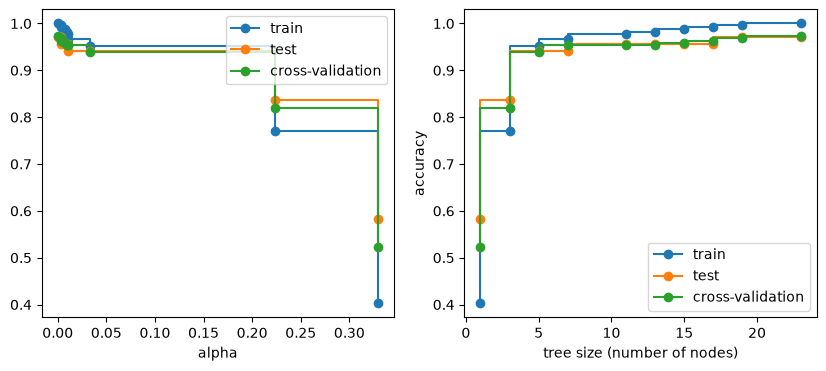

Best alpha: 0.0
Best tree size (nodes): 23


In [20]:
# Code for your answer here

train_scores = [clf.score(X_train, y_train) for clf in clfs]
test_scores = [clf.score(X_test, y_test) for clf in clfs]
cv_scores = gs.cv_results_['mean_test_score']

fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].set_xlabel("alpha")
ax[0].plot(ccp_alphas, train_scores, marker="o", label="train", drawstyle="steps-post")
ax[0].plot(ccp_alphas, test_scores, marker="o", label="test", drawstyle="steps-post")
ax[0].plot(ccp_alphas, cv_scores, marker="o", label="cross-validation", drawstyle="steps-post")
ax[0].legend()
ax[1].set_xlabel("tree size (number of nodes)")
ax[1].set_ylabel("accuracy")
ax[1].plot(node_counts, train_scores, marker="o", label="train", drawstyle="steps-post")
ax[1].plot(node_counts, test_scores, marker="o", label="test", drawstyle="steps-post")
ax[1].plot(node_counts, cv_scores, marker="o", label="cross-validation", drawstyle="steps-post")
ax[1].legend()
plt.show()

print("Best alpha:", gs.best_params_['ccp_alpha'])

best_estimator = gs.best_estimator_
best_tree_size = best_estimator.tree_.node_count # or use the corresponding value in node_counts
print(f"Best tree size (nodes): {best_tree_size}")

_Type your answer here_

Looking at the plots we see in order to get the highest accuracy we should choose alpha = 0, as well as that the results also show that. The number of nodes that maximises the accuracy is 23 (from code), which we can see also on the grah as accuracy is increasing as number of nodes is increasing.

### 🚩 Exercise 7 (CORE)

For your chosen value of $\alpha$ fit and visualise the tree. How does it compare to the shallow and deep tree that we initialy fit?

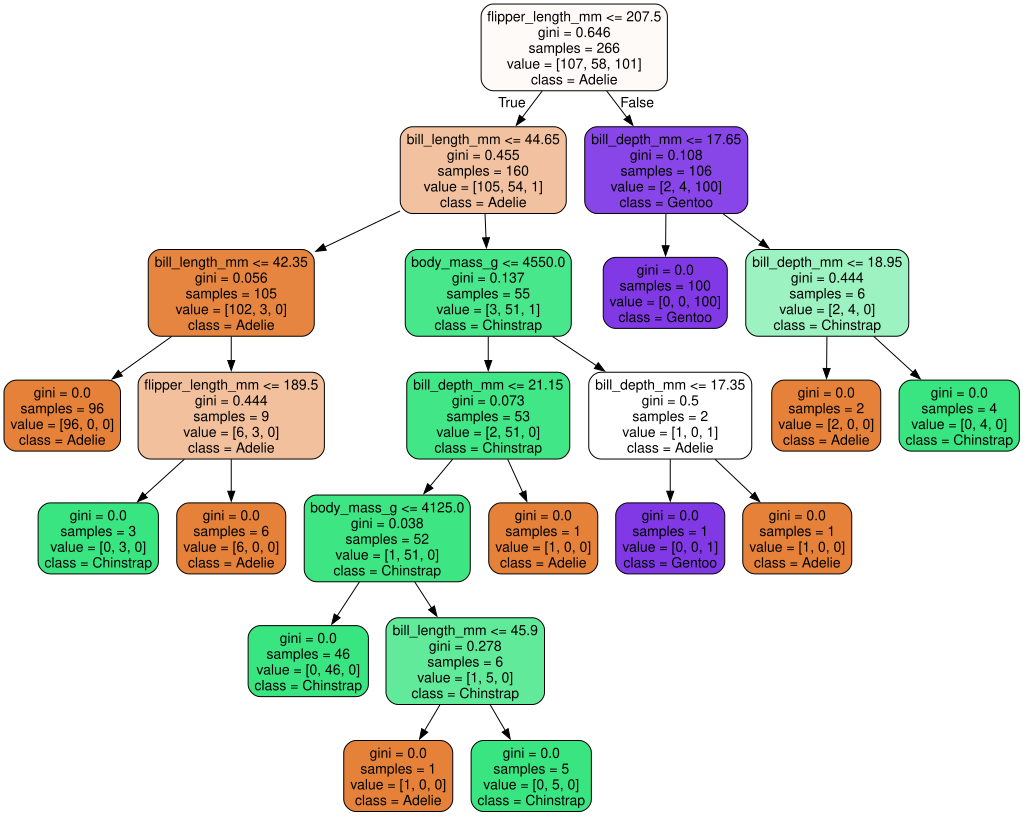

In [21]:
# NOTE: call your tree clf or change to your name of the pruned tree when computing feature importances before exercise 12

# Code for your answer here

tree_clf_3 = DecisionTreeClassifier(random_state=0,ccp_alpha = 0)
tree_clf_3.fit(X_train, y_train)

# Plot the decision tree
tree_data = export_graphviz(
 tree_clf_3,
 rounded = True, filled = True, feature_names=X_train.columns, class_names = tree_clf_3.classes_
 )
graphviz.Source(tree_data) 

_Type your answer here_

There many more branches in this tree,as well as many more final nodes compared to the shallow tree. However, looking at the deeper tree, we see this is a lot more similar. With many of the branches of the trees being the same, witha  few different intricasies like the bottom node being slightly different layout. 

# Ensembles <a id='majVot'></a> 

Ensembles combine the predictions of several base estimators to improve generalization and robustness, compared with a single estimator. A number of ensemble methods are available in `sklearn`, and for an overview, see 
https://scikit-learn.org/stable/modules/ensemble.html#. However, we only have time to cover a subset of ensemble methods, namely, **bagging**, **random forests**, and **voting**.

## Bagging

A bagging classifier is an ensemble of base classifiers, each fit on random subsets of a dataset. Their predictions are then pooled or aggregated to form a final prediction. To apply bagging to decision trees, we simply construct 
(i) decision trees using bootstrapped training sets,
(ii) agregated the predictions (either by averaging the probabilities or by majority vote).

Bagging is typically used as a way to reduce the variance of a high-variance estimator (e.g. a decision tree). The parameter `n_estimators` contols the number of bootstrapped datasets, and hence the number of estimators in the ensemble. While bagging is when sampling is performed with replacement, the `sklearn` implementation allows for more general constructions of the random subsets of the data: 

- Pasting is when the sampling is done without replacement and is designed to use smaller sample sizes than the training dataset (useful when the training dataset does not fit into memory). Pasting can be performed with `BaggingClassifier` by setting the options `bootstrap=FALSE` and `max_samples` either to an integer or a float representing the sample size of the random subset as a proportion of training points. 

- Random Subspaces is when random subsets of the dataset are drawn as random subsets of the features. Random Subspaces can be performed with `BaggingClassifier` by setting the options `bootstrap=FALSE` and `max_features` either to an integer or a float representing the number of features in the random subset as a proportion of the number of features in the training data. 

- Random Patches is when random subsets of the dataset are drawn based on random subsets of both the features and samples, and can be constructed by combining the options above. 

Averaging methods generally work best when the classifiers are diverse, and they have been shown to give impressive improvements in accuracy by combining together hundreds or even thousands of trees into a single procedure.

Note that while the default estimator in `BaggingClassifier` is a decision tree, other classifiers can be combined by specifying the option `estimator`. Also note that in `sklearn`'s implementation, the final predictions are obtained by averaging the prediction probabilities across estimators, with majority voting only used for estimators that don't provide probabilistic outputs. 

For more details, see:  
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html


### 🚩 Exercise 8  (CORE)

- Fit a bagged classifier to the data that combines 10 decision trees.

- Plot the confusion matrix on the both test and training data for both your pruned tree and bagged classifier. Comment on the advantages and disadvantages of the pruned tree vs bagged classifier briefly. 

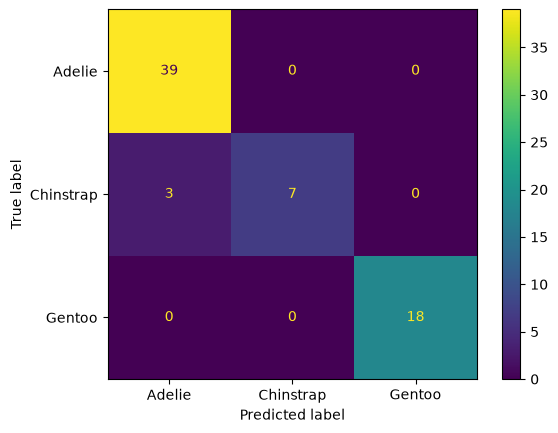

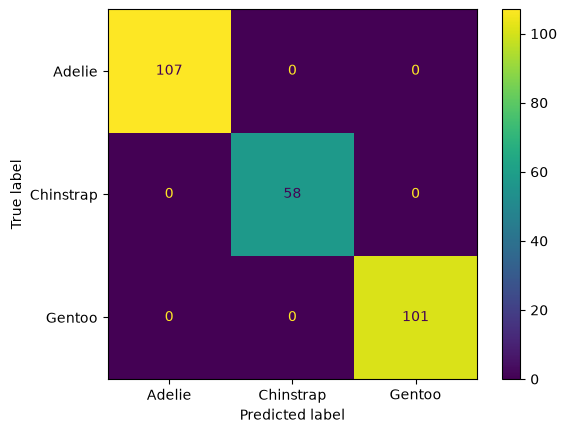

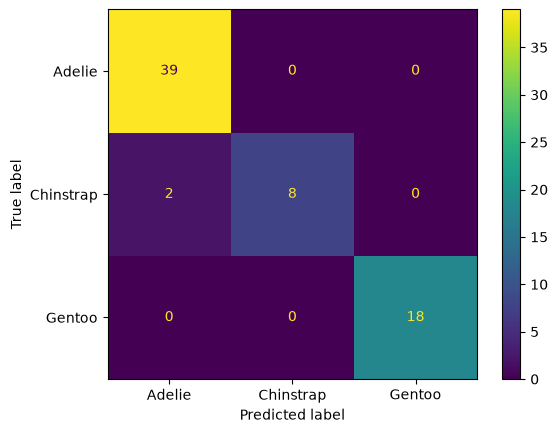

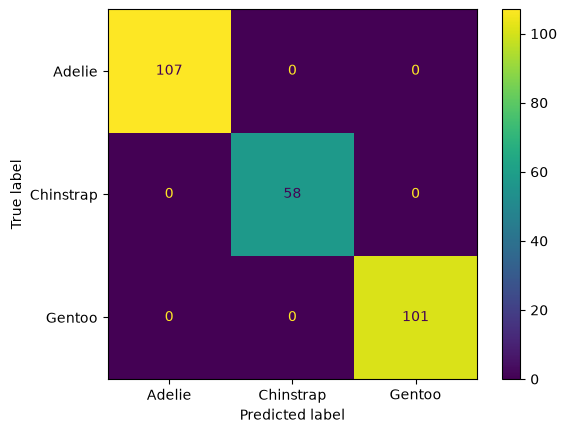

In [22]:
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import ConfusionMatrixDisplay

# Code for your answer here

clf_b = BaggingClassifier(n_estimators=10)
clf_b.fit(X_train, y_train)

predictions = clf_b.predict(X_test)

# Display confusion matrix for bagged classifier
disp_test = ConfusionMatrixDisplay.from_predictions(y_test, predictions)
#disp_test.plot()

disp_training= ConfusionMatrixDisplay.from_predictions(y_train, clf_b.predict(X_train))
#disp_training.plot()


#Now same for pruned tree
disp_test_p = ConfusionMatrixDisplay.from_predictions(y_test, tree_clf_3.predict(X_test))
#disp_test_p.plot()

disp_training_p = ConfusionMatrixDisplay.from_predictions(y_train, tree_clf_3.predict(X_train))
##disp_training_p.plot()

_Type your answer here_

For both methods, pruned tree and bagged classifier we observe that for the training and test data we get the same confusion matrix. Between the methods themselves we see significant differneces though. We see the pruned version has no false outcomes when using the training data, and when using test data has two off diagonal entires, indicating not a perfect fit. The bagged classifier has the same off diagonal singular, False Chinstap label but, for the training data. As well as that, when using the test data there are three off diagonal entries indicating a worse fit than the pruning which only had two.. This makes sense has it samples over smaller data.

### 🚩 Exercise 9  (CORE)

For the range of `n_estimators` provided below: 
- Fit the bagged trees and compute the training accuracy, test accuracy, and out-of-bag scores. 
- Plot all three metrics as a function of the number of estimators. 
- Comment on the results and suggest a suitable number of estimators for this data.

C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\ensemble\_bagging.py:917: UserWarning: Some inputs do not have OOB scores. This probably means too few estimators were used to compute any reliable oob estimates.
  warn(
C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\ensemble\_bagging.py:923: RuntimeWarning: invalid value encountered in divide
  oob_decision_function = predictions / predictions.sum(axis=1)[:, np.newaxis]
C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\ensemble\_bagging.py:917: UserWarning: Some inputs do not have OOB scores. This probably means too few estimators were used to compute any reliable oob estimates.
  warn(
C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\ensemble\_bagging.py:923: RuntimeWarning: invalid value encountered in divide
  oob_decision_function = predictions / predictions.sum(axis=1)[:, np.newaxis]
C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sk

Bagging with 1 estimators:
Training accuracy: 0.9849624060150376
Test accuracy: 0.9402985074626866
Out-of-bag score: 0.6127819548872181
Bagging with 5 estimators:
Training accuracy: 0.9924812030075187
Test accuracy: 0.9701492537313433
Out-of-bag score: 0.9360902255639098
Bagging with 10 estimators:
Training accuracy: 1.0
Test accuracy: 0.9701492537313433
Out-of-bag score: 0.9624060150375939
Bagging with 20 estimators:
Training accuracy: 1.0
Test accuracy: 0.9701492537313433
Out-of-bag score: 0.9661654135338346
Bagging with 50 estimators:
Training accuracy: 1.0
Test accuracy: 0.9701492537313433
Out-of-bag score: 0.981203007518797


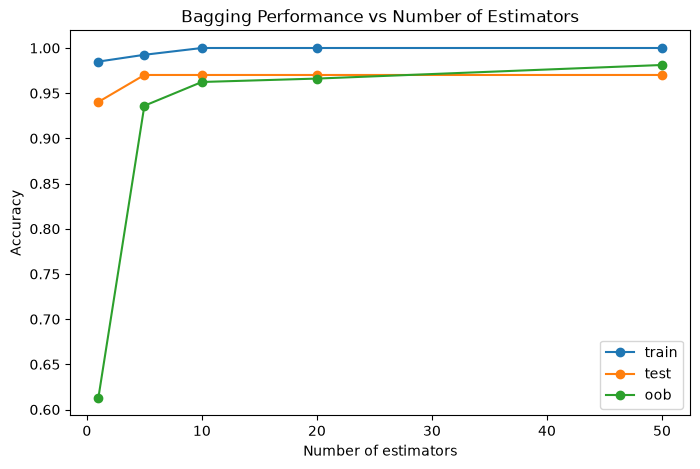

In [23]:
n_est = np.array([1,5,10,20,50],dtype=int)

# Code for your answer here
train_scores = []
test_scores = []
oob_scores = []

for n in n_est:
    clf_b = BaggingClassifier(n_estimators=n, oob_score=True, random_state=0)
    clf_b.fit(X_train, y_train)
    print(f"Bagging with {n} estimators:")
    print("Training accuracy:", clf_b.score(X_train, y_train))
    print("Test accuracy:", clf_b.score(X_test, y_test))
    print("Out-of-bag score:", clf_b.oob_score_)

    train_scores.append(clf_b.score(X_train, y_train))
    test_scores.append(clf_b.score(X_test, y_test))
    oob_scores.append(clf_b.oob_score_)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(n_est, train_scores, marker="o", label="train")
ax.plot(n_est, test_scores, marker="o", label="test")
ax.plot(n_est, oob_scores, marker="o", label="oob")

ax.set_xlabel("Number of estimators")
ax.set_ylabel("Accuracy")
ax.set_title("Bagging Performance vs Number of Estimators")
ax.legend()
plt.show()

_Type your answer here_

After both reviewing both the numerical values, as well as the graph we see differnet patterns between the scores as a function of estimators. Regarding the test training data, we see it starts the highest and quickly reaches one and levels out at 10 estimators. The test scores start a little lower but level at around 0.97, out do so more quickly at around 5 estimators. Finally the oob score starts much lower, but still manages to increasie quick enough to 'level' out at 10 estimators. Note: overtakes at 50 estimators.

My suggested number of estimators would be 10, as botht he training and test scores level out here, and the oob score, essentially levels out. Adding more estimators will increase coputational time so this seems a right number.

### Bagging: low diversity in estimators

Bagging alone may not produce very diverse trees, and thus may result in only modest improvements in accuracy.  In particular, if there is a strong set of predictors in the data, then the bagged trees will look quite similar to each other and predictions will be highly correlated. Averaging highly correlated quantities does not lead to a large reduction in variance and provides on very small improvements in predictions.

Run the following code below, the print out the feature and threshold used for the first split for each of the trees in our ensemble. Notice how most of trees use the same first splitting rule. 

In [24]:
# print out the first split for all trees in the bagged model
for i in range(10):
    print('Estimator: ', i+1, 
          ', First split feature: ', clf_b.estimators_[i].tree_.feature[0], 
          ', First split threshold: ', clf_b.estimators_[i].tree_.threshold[0])

Estimator:  1 , First split feature:  2 , First split threshold:  207.5
Estimator:  2 , First split feature:  2 , First split threshold:  206.5
Estimator:  3 , First split feature:  2 , First split threshold:  206.5
Estimator:  4 , First split feature:  2 , First split threshold:  206.5
Estimator:  5 , First split feature:  0 , First split threshold:  43.25
Estimator:  6 , First split feature:  1 , First split threshold:  16.449999809265137
Estimator:  7 , First split feature:  2 , First split threshold:  207.5
Estimator:  8 , First split feature:  0 , First split threshold:  42.30000114440918
Estimator:  9 , First split feature:  2 , First split threshold:  207.0
Estimator:  10 , First split feature:  2 , First split threshold:  207.0


## Random Forests

Random forests is one of the most widely used machine learning algorithms. A random forest is an ensemble that fits a number of decision tree classifiers on various random subsets of the data (Random Patches) and uses averaging to improve the predictive accuracy and control overfitting. Random forests are essentally bagged tree classifiers, but improve the diversity and decorrelate the trees compared with bagging by using a random sample of features each time a split in a tree is considered. The random forest algorithm can therefore be summarised as:

- Draw a random bootstrap sample of the training data.

- Grow a decision tree from the bootstrap data. At each node:
    * Randomly select a subset of features without replacement (defaults to the square root of the total number of features).
    * Split the node using the feature and threshold that provides the best split according to the objective function.

- Repeat the steps above for the desired number of bootstrapped datasets (estimators in the ensemble).

- Aggregate the predictions (`sklearn`'s `RandomForestClassifier` aggregates the prediction probabilities).

### Parameters

Important parameters include:

- `max_features`: specifies that number of random features to consider at each split. If set to the total number of features, then it is simply bagging. 
- `n_estimators`: number of trees in the ensemble; larger is generally better as averaging more trees will yield a more robust ensemble. 
- `max_samples`: sample size of the bootstrap dataset (useful when the training set is large to reduce memory and computational cost).

 By default, large and complex trees are grown for each bootstrapped data. While these trees tend to have high variance and overfit to the training data, aggregation reduces variance and improves predictive accuracy. If desired, the complexity of the trees can also be limited by setting the parameters of the decision trees  (e.g. `max_depth`, `max_leaf_nodes`); again this may be useful to reduce memory and computational cost.

### 🚩 Exercise 10 (CORE)

- Fit a random forest classifer that includes 10 trees in the ensemble. 
- Print the splitting rule (feature and threshold) for each estimator. How does this compare to the bagged model?

In [25]:
from sklearn.ensemble import RandomForestClassifier

# Code for your answer here

rfc = RandomForestClassifier(n_estimators=10, bootstrap=True, random_state=0)
rfc.fit(X_train, y_train)

for i in range(10):
    print('Estimator: ', i+1, 
          ', First split feature: ', rfc.estimators_[i].tree_.feature[0], 
          ', First split threshold: ', rfc.estimators_[i].tree_.threshold[0])

Estimator:  1 , First split feature:  0 , First split threshold:  43.25
Estimator:  2 , First split feature:  0 , First split threshold:  43.19999885559082
Estimator:  3 , First split feature:  0 , First split threshold:  43.10000038146973
Estimator:  4 , First split feature:  1 , First split threshold:  16.399999618530273
Estimator:  5 , First split feature:  0 , First split threshold:  43.25
Estimator:  6 , First split feature:  1 , First split threshold:  16.449999809265137
Estimator:  7 , First split feature:  1 , First split threshold:  16.449999809265137
Estimator:  8 , First split feature:  0 , First split threshold:  42.30000114440918
Estimator:  9 , First split feature:  1 , First split threshold:  16.449999809265137
Estimator:  10 , First split feature:  2 , First split threshold:  207.0


_Type your answer here_

Compared to the bagged classifier that had mostly features 2 as decision paramteer, using random forest we now have a good mix. Mostly zeros and ones, and a 2. This has removed the correlation the bagging internally output by random sampling.

### 🚩 Exercise 11 (CORE)

- Fit a random forest to your data, using the OOB error to tune the number of features considered at each split, for **max_features** in $[2, 3, 4]$. What is the optimal number of features?
- Visualise the confusion matrix on the train and test data. 

Random Forest with max_features=2:
optimal feature [0.40053615 0.23803657 0.29031983 0.07110745]
Out-of-bag score: 0.9774436090225563

Random Forest with max_features=3:
optimal feature [0.40526474 0.23530995 0.30596286 0.05346246]
Out-of-bag score: 0.9849624060150376

Random Forest with max_features=4:
optimal feature [0.41485411 0.22209211 0.32191508 0.0411387 ]
Out-of-bag score: 0.9774436090225563



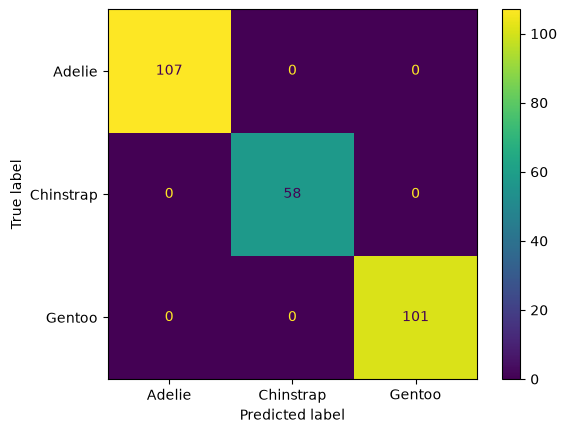

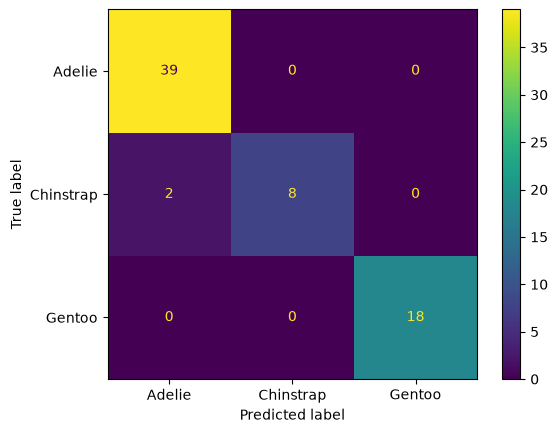

In [33]:
# Note: let rf be the name your random forest object with the optimal max_features or change the name in exercise 12

m_features = [2,3,4]
for m in m_features:
    rfc = RandomForestClassifier(max_features=m, bootstrap=True, random_state=0, oob_score=True)
    rfc.fit(X_train, y_train)
    print(f"Random Forest with max_features={m}:")
    print("optimal feature", rfc.feature_importances_)
    print("Out-of-bag score:", rfc.oob_score_)
    print()

    #rf_training= ConfusionMatrixDisplay.from_predictions(y_train, rfc.predict(X_train))
    #rf_test= ConfusionMatrixDisplay.from_predictions(y_test, rfc.predict(X_test))

#Largest OOB score when max feature is 3, thus 3 is optimal number of features. Thus we plot confusion matrix for this:

rfc = RandomForestClassifier(max_features=3, bootstrap=True, random_state=0, oob_score=True)
rfc.fit(X_train, y_train)

rf_training= ConfusionMatrixDisplay.from_predictions(y_train, rfc.predict(X_train))
rf_test= ConfusionMatrixDisplay.from_predictions(y_test, rfc.predict(X_test))

#rfc = RandomForestClassifier(bootstrap=True, random_state=0, oob_score=True)
#rfc.fit(X_train, y_train)

#print(rfc.feature_importances_)
#print(rfc.oob_score_)

#rf_training= ConfusionMatrixDisplay.from_predictions(y_train, rfc.predict(X_train))
#rf_test= ConfusionMatrixDisplay.from_predictions(y_test, rfc.predict(X_test))



### Feature Importance <a id='feImport'></a> 

The fitted `RandomForestClassifier` also has an attribute `feature_importances_`, that reflects the relative rank (i.e. depth) and predictive power of a feature, averaged across all trees in the ensemble. For further details, see https://scikit-learn.org/stable/modules/ensemble.html#feature-importance-evaluation, and for an example, see https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html.

Let's start by visualising the feature importances for our pruned tree in exercise 7 (note: replace `clf` with the name of your tree from exercise 7, if not already called `clf`). Notice how this reflects the depth of the feature and impurity decrease.

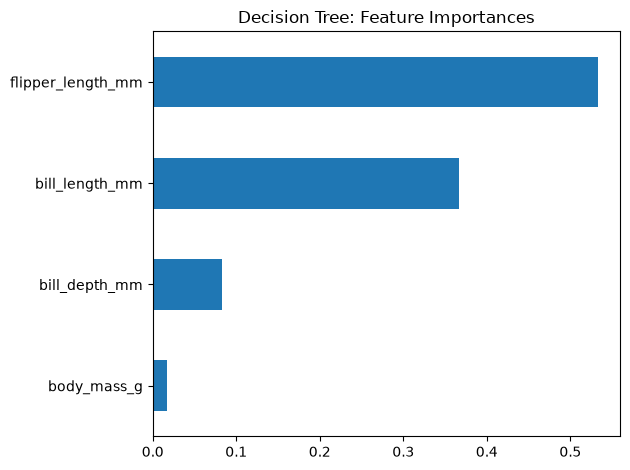

In [30]:
# NOTE: change clf to name of your pruned tree in exercise 7

# Extract feature names
feature_names = tree_clf_3.feature_names_in_ 

# Create a pandas series with the feature importances
importances = pd.Series(
    tree_clf_3.feature_importances_, index=feature_names
).sort_values(ascending=True)

# Plot the feature importances
ax = importances.plot.barh()
ax.set_title("Decision Tree: Feature Importances")
ax.figure.tight_layout()


### 🚩 Exercise 12  (EXTRA - Feedback will be provided)

- Run the following code to plot the feature importance (averaged across all trees along with the standard deviation). 
- Visualise the correlation matrix of the features. 
- Has the ranking of the features changed comparing the pruned tree to the random forest? Does the correlation matrix provide any insight on why?

In [32]:
# Note: change rf to the name your random forest object in exercise 12

# Compute the standard deviation 
std = np.std([tree.feature_importances_ for tree in tree_clf_3.estimators_], axis=0)

# Create a pandas series with the feature importances
importances_rf = pd.Series(
    tree_clf_3.feature_importances_, index=feature_names
).sort_values(ascending=True)

# Plot the feature importances
ax = importances_rf.plot.barh(xerr=std)
ax.set_title("Random Forest: Feature Importances")
ax.figure.tight_layout()

AttributeError: 'DecisionTreeClassifier' object has no attribute 'estimators_'

In [ ]:
# Code for your answer here

_Type your answer here_

## Voting Classifier

While bagging and random forests focused on creating an ensemble of the same estimator (e.g. trees) fit on different random subsets of the data, the idea behind **voting** is to combine different estimators. The predictions then can be aggregated either by using a majority vote or by averaging predicted probabilities (soft vote). This can be useful for a set of equally well performing models in order to balance out their individual weaknesses.

In the `VotingClassifier`, the default is to aggregate predictions with **hard voting** (i.e. `voting='hard'` by default), which simply looks at the tally of votes received by each class across the estimators in the ensemble. Instead, **soft voting** (i.e. `voting='soft'`) averages the predicted probabilities across the estimators in the ensemble.

For further details, please see the documentation from here: https://scikit-learn.org/stable/modules/ensemble.html#voting-classifier

### 🚩 Exercise 13  (EXTRA)

- Create a voting classifier that combines your pruned tree, random forests, logistic regression, and support vector classifier.

- How does the accuracy on the test data compare across each model individually and the voting classifier?

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

# Code for your answer here

_Type your answer here_

### 🚩 Exercise 14 (CORE)

Have you used any form of generative AI when working on this assessment? If so, describe how you used which tool, and what you have learned from it.

_Type your answer here_

There was some use of AI when doing this workshop. I mainly used it for my plots, for example in Ex9. I kep accidenlt puttoing my plots inside my loops meaning it was double printing but at least now i know not to do that, and just store in a list. It was elm i used.

# Completing the Worksheet

At this point you have hopefully been able to complete all the CORE exercises and attempted the EXTRA ones. Now is a good time to check the reproducibility of this document by restarting the notebook's kernel and rerunning all cells in order.

Before generating the PDF, please **change 'Student 1', 'Student 2' and 'Student 3' at the top of the notebook to include your name(s)**.

Once that is done and you are happy with everything, you can then run the following cell to generate your PDF. 

In [34]:
!jupyter nbconvert --to pdf mlp_week08.ipynb 

Error executing Jupyter command 'nbconvert': [WinError 4551] An Application Control policy has blocked this file
